**PART 4 — GenAI: Follow-up Notes Analysis**

**Task 4.1 One Validated Gemini API Call**

In [ ]:

import pandas as pd
import json
import time

from google import genai
from google.genai import types
from pydantic import BaseModel, Field
from typing import Literal

print("Task 4.1 Libraries Imported Successfully!")


Task 4.1 Libraries Imported Successfully!


In [ ]:

notes = pd.read_csv("/content/followup_notes.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", notes.shape)

print("\nFirst 5 Notes:")
print(notes.head())


Dataset Loaded Successfully!
Dataset Shape: (30, 3)

First 5 Notes:
  note_id appointment_id                                          note_text
0    N001          A0872  Patient said she never got any reminder messag...
1    N002          A0897  Lives far from the clinic and could not find a...
2    N003          A0526  Patient felt the consultation fee was too high...
3    N004          A0926                                                NaN
4    N005          A0534  Had high fever and body ache on the day, staye...


In [ ]:

import getpass

API_KEY = getpass.getpass("Enter your Gemini API Key: ")

client = genai.Client(api_key=API_KEY)

MODEL_NAME = "gemini-3.8-flash"

print("Gemini API Connected Successfully!")
print("Model:", MODEL_NAME)


Enter your Gemini API Key: ··········
Gemini API Connected Successfully!
Model: gemini-3.8-flash


In [ ]:

# TASK 4.1 — JSON Schema Creation

from pydantic import BaseModel, Field
from typing import Literal

class FollowupAnalysis(BaseModel):

    root_cause: Literal[
        "illness_or_emergency",
        "work_or_schedule",
        "distance_or_transport",
        "forgot_or_no_reminder",
        "cost_or_fee",
        "other"
    ]

    confidence: float = Field(
        ge=0,
        le=1
    )

    summary: str

    recommended_action: str


print("JSON Schema Created Successfully!")

print("\nSchema Fields:")
print(list(FollowupAnalysis.model_fields.keys()))


JSON Schema Created Successfully!

Schema Fields:
['root_cause', 'confidence', 'summary', 'recommended_action']


In [ ]:

# TASK 4.1 — SYSTEM PROMPT CREATION

SYSTEM_TEXT = """
You are an expert Healthcare Appointment
Follow-up Analyst.

Your task is to analyze patient notes and
identify the main reason for missed appointments.

Follow these rules:

1. Identify the primary root cause.
2. Select only one root cause from the
   predefined categories.
3. Provide a confidence score between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information that is not
   mentioned in the patient note.
7. If the reason is unclear, classify it as other.

Root Cause Categories:

- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

Return structured output following the
provided JSON Schema.
"""

print("System Prompt Created Successfully!")
print("\nSystem Prompt:")
print(SYSTEM_TEXT)


System Prompt Created Successfully!

System Prompt:

You are an expert Healthcare Appointment
Follow-up Analyst.

Your task is to analyze patient notes and
identify the main reason for missed appointments.

Follow these rules:

1. Identify the primary root cause.
2. Select only one root cause from the
   predefined categories.
3. Provide a confidence score between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information that is not
   mentioned in the patient note.
7. If the reason is unclear, classify it as other.

Root Cause Categories:

- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

Return structured output following the
provided JSON Schema.



In [ ]:

# TASK 4.1 — One Validated Gemini API Call

def analyse_note(note_text):

    prompt = f"""
    Analyze the following healthcare appointment note.

    Patient Note:
    {note_text}

    Return the analysis according to the JSON Schema.
    """

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            system_instruction=SYSTEM_TEXT,
            response_mime_type="application/json",
            response_schema=FollowupAnalysis
        )
    )

    # Pydantic Validation
    result = FollowupAnalysis.model_validate_json(
        response.text
    )

    return result.model_dump()


print("Gemini Analysis Function Created Successfully!")


Gemini Analysis Function Created Successfully!


In [ ]:

# Test with N001

note_001 = notes.loc[
    notes["note_id"] == "N001",
    "note_text"
].iloc[0]

result = analyse_note(note_001)

print("Original Note:")
print(note_001)

print("\nGemini AI Analysis:")
print(result)

print("\nPydantic Validation Successful!")


Original Note:
Patient said she never got any reminder message and completely forgot about the visit. Wants to rebook for next week.

Gemini AI Analysis:
{'root_cause': 'forgot_or_no_reminder', 'confidence': 0.98, 'summary': 'The patient missed the visit because they forgot about it after not receiving an appointment reminder.', 'recommended_action': 'Verify and update patient contact details and notification preferences in the system, and reschedule the visit for next week as requested.'}

Pydantic Validation Successful!


**Task 4.2 — CRAFT Prompt Engineering**

In [ ]:

import json
import pandas as pd
from google.genai import types

# Select first 10 patient notes
notes_10 = notes.head(10).copy()

# Select only N007 and N009
selected_notes = notes_10[
    notes_10["note_id"].isin(["N007", "N009"])
].copy()

print("Task 4.2 — CRAFT Prompt Engineering")
print("Selected Notes:", len(selected_notes))
print("\nSelected Note IDs:")
print(selected_notes["note_id"].tolist())

print("\nSelected Notes Data:")
print(selected_notes[["note_id", "appointment_id", "note_text"]].to_string(index=False))


Task 4.2 — CRAFT Prompt Engineering
Selected Notes: 2

Selected Note IDs:
['N007', 'N009']

Selected Notes Data:
note_id appointment_id                                                                 note_text
   N007          A0333                  Bhool gaya, SMS nahi aaya tha. Dobara booking karni hai.
   N009          A0977 Phone was switched off, could not reach the patient after three attempts.


In [ ]:

# Task 4.2 — CRAFT Prompt Engineering

def generate_craft_prompt(note_text):

    prompt = f"""
CONTEXT:
A healthcare clinic wants to understand why patients
miss their scheduled appointments.

ROLE:
You are an expert Healthcare Appointment Follow-up Analyst.

ACTION:
Analyze the patient note and identify the main reason
for the missed appointment.

Follow these rules:
1. Identify only one primary root cause.
2. Select from the predefined categories.
3. Provide confidence between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information.
7. If unclear, classify as other.

ROOT CAUSE CATEGORIES:
- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

FORMAT:
Return valid JSON with exactly these fields:
- root_cause
- confidence
- summary
- recommended_action

TONE:
Professional, clear, concise and evidence-based.

PATIENT NOTE:
{note_text}
"""

    return prompt


print("CRAFT Prompt Created Successfully!")

# Preview prompt for N007
sample_note = selected_notes.iloc[0]["note_text"]

craft_prompt = generate_craft_prompt(sample_note)

print("\nCRAFT Prompt Preview:")
print(craft_prompt)


CRAFT Prompt Created Successfully!

CRAFT Prompt Preview:

CONTEXT:
A healthcare clinic wants to understand why patients
miss their scheduled appointments.

ROLE:
You are an expert Healthcare Appointment Follow-up Analyst.

ACTION:
Analyze the patient note and identify the main reason
for the missed appointment.

Follow these rules:
1. Identify only one primary root cause.
2. Select from the predefined categories.
3. Provide confidence between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information.
7. If unclear, classify as other.

ROOT CAUSE CATEGORIES:
- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

FORMAT:
Return valid JSON with exactly these fields:
- root_cause
- confidence
- summary
- recommended_action

TONE:
Professional, clear, concise and evidence-based.

PATIENT NOTE:
Bhool gaya, SMS nahi aaya tha. Dobara booking karni hai.



In [ ]:
import json
import time
from google.genai import types

# V2 CRAFT Analysis Function

def generate_v2(note_text):

    prompt = f"""
CONTEXT:
A healthcare clinic wants to understand why patients
miss their scheduled appointments.

ROLE:
You are an expert Healthcare Appointment Follow-up Analyst.

ACTION:
Analyze the patient note and identify the main reason
for the missed appointment.

Follow these rules:
1. Identify only one primary root cause.
2. Select from predefined categories.
3. Provide confidence between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information.
7. If unclear, classify as other.

ROOT CAUSE CATEGORIES:
- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

PATIENT NOTE:
{note_text}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=FollowupAnalysis
        )
    )

    return response.parsed

In [ ]:
# Select only N007 and N009

selected_notes = notes_10[
    notes_10["note_id"].isin(["N007", "N009"])
].copy()

v2_results = []

for _, row in selected_notes.iterrows():

    note_id = row["note_id"]
    note_text = row["note_text"]

    print(f"Processing {note_id}...")

    try:
        result = generate_v2(note_text)

        result_dict = (
            result.model_dump()
            if hasattr(result, "model_dump")
            else dict(result)
        )

        result_dict["note_id"] = note_id

        v2_results.append(result_dict)

        print(f"{note_id} Successfully Analysed")

    except Exception as e:
        print(f"{note_id} Error: {e}")

    time.sleep(2)

print("\nTotal Successful:", len(v2_results))

Processing N007...
N007 Successfully Analysed
Processing N009...
N009 Successfully Analysed

Total Successful: 2


In [ ]:
# Create V2 Results DataFrame

v2_df = pd.DataFrame(v2_results)

if not v2_df.empty:

    v2_df = v2_df[
        [
            "note_id",
            "root_cause",
            "confidence",
            "summary",
            "recommended_action"
        ]
    ]

    print("V2 CRAFT PROMPT RESULTS")

    display(v2_df)

else:
    print("No successful V2 analyses found.")

V2 CRAFT PROMPT RESULTS


,note_id,root_cause,confidence,summary,recommended_action
0,N007,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Check the SMS notification delivery status for...
1,N009,other,0.95,The clinic could not contact the patient after...,Attempt outreach through alternative contact m...


**Task 4.3 — Prompt Comparison**

In [ ]:
# V1 Original Prompt Function

def generate_v1(note_text):

    prompt = f"""
You are an expert Healthcare Appointment Follow-up Analyst.

Your task is to analyze patient notes and identify
the main reason for missed appointments.

Follow these rules:

1. Identify the primary root cause.
2. Select only one root cause from predefined categories.
3. Provide a confidence score between 0 and 1.
4. Write a short and clear summary.
5. Recommend a practical action for the clinic.
6. Do not invent information.
7. If the reason is unclear, classify it as other.

Root Cause Categories:
- illness_or_emergency
- work_or_schedule
- distance_or_transport
- forgot_or_no_reminder
- cost_or_fee
- other

Patient Note:
{note_text}
"""

    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=prompt,
        config=types.GenerateContentConfig(
            response_mime_type="application/json",
            response_schema=FollowupAnalysis
        )
    )

    return response.parsed

print("V1 Original Prompt Function Created Successfully!")

V1 Original Prompt Function Created Successfully!


In [ ]:
# Select N007 and N009

v1_results = []

for _, row in selected_notes.iterrows():

    note_id = row["note_id"]
    note_text = row["note_text"]

    print(f"Processing {note_id}...")

    try:
        result = generate_v1(note_text)

        result_dict = (
            result.model_dump()
            if hasattr(result, "model_dump")
            else dict(result)
        )

        result_dict["note_id"] = note_id

        v1_results.append(result_dict)

        print(f"{note_id} Successfully Analysed")

    except Exception as e:
        print(f"{note_id} Error: {e}")

    time.sleep(2)

print("\nTotal V1 Successful:", len(v1_results))

Processing N007...
N007 Successfully Analysed
Processing N009...
N009 Successfully Analysed

Total V1 Successful: 2


In [ ]:
# Create V1 DataFrame

v1_df = pd.DataFrame(v1_results)

if not v1_df.empty:

    v1_df = v1_df[
        [
            "note_id",
            "root_cause",
            "confidence",
            "summary",
            "recommended_action"
        ]
    ]

    print("V1 ORIGINAL PROMPT RESULTS")

    display(v1_df)

else:
    print("No V1 results available.")

V1 ORIGINAL PROMPT RESULTS


,note_id,root_cause,confidence,summary,recommended_action
0,N007,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Verify the patient's phone number and notifica...
1,N009,other,0.95,The clinic made three unsuccessful attempts to...,Attempt to contact the patient via an alternat...


In [ ]:
print("V1 RESULTS:")
display(v1_df)

print("Total V1:", len(v1_df))

V1 RESULTS:


,note_id,root_cause,confidence,summary,recommended_action
0,N007,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Verify the patient's phone number and notifica...
1,N009,other,0.95,The clinic made three unsuccessful attempts to...,Attempt to contact the patient via an alternat...


Total V1: 2


In [ ]:
print("V2 RESULTS:")
display(v2_df)

print("Total V2:", len(v2_df))

V2 RESULTS:


,note_id,root_cause,confidence,summary,recommended_action
0,N007,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Check the SMS notification delivery status for...
1,N009,other,0.95,The clinic could not contact the patient after...,Attempt outreach through alternative contact m...


Total V2: 2


In [ ]:
comparison_df = v1_df.merge(
    v2_df,
    on="note_id",
    suffixes=("_V1", "_V2")
)

comparison_df["root_cause_match"] = (
    comparison_df["root_cause_V1"] ==
    comparison_df["root_cause_V2"]
)

display(comparison_df)

print(
    "Root Cause Agreement:",
    comparison_df["root_cause_match"].sum(),
    "/",
    len(comparison_df)
)

,note_id,root_cause_V1,confidence_V1,summary_V1,recommended_action_V1,root_cause_V2,confidence_V2,summary_V2,recommended_action_V2,root_cause_match
0,N007,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Verify the patient's phone number and notifica...,forgot_or_no_reminder,0.98,The patient missed the appointment because the...,Check the SMS notification delivery status for...,True
1,N009,other,0.95,The clinic made three unsuccessful attempts to...,Attempt to contact the patient via an alternat...,other,0.95,The clinic could not contact the patient after...,Attempt outreach through alternative contact m...,True


Root Cause Agreement: 2 / 2


In [ ]:
total_notes = len(comparison_df)

agreement = comparison_df["root_cause_match"].sum()

agreement_pct = (agreement / total_notes) * 100

print("Total Notes:", total_notes)
print("Matching Root Causes:", agreement)
print("Agreement Percentage:", round(agreement_pct, 2), "%")

Total Notes: 2
Matching Root Causes: 2
Agreement Percentage: 100.0 %


In [ ]:
confidence_comparison = comparison_df[
    ["note_id", "confidence_V1", "confidence_V2"]
].copy()

confidence_comparison["confidence_difference"] = (
    confidence_comparison["confidence_V2"] -
    confidence_comparison["confidence_V1"]
)

display(confidence_comparison)

,note_id,confidence_V1,confidence_V2,confidence_difference
0,N007,0.98,0.98,0.0
1,N009,0.95,0.95,0.0


In [ ]:
comparison_df.to_csv(
    "V1_V2_Prompt_Comparison.csv",
    index=False
)

print("V1 vs V2 Comparison Saved Successfully!")

V1 vs V2 Comparison Saved Successfully!


In [ ]:
print("FINAL PROMPT COMPARISON")

print("V1 Total Results:", len(v1_df))
print("V2 Total Results:", len(v2_df))

print("Root Cause Agreement:",
      round(agreement_pct, 2), "%")

print("Average V1 Confidence:",
      round(v1_df["confidence"].mean(), 3))

print("Average V2 Confidence:",
      round(v2_df["confidence"].mean(), 3))

FINAL PROMPT COMPARISON
V1 Total Results: 2
V2 Total Results: 2
Root Cause Agreement: 100.0 %
Average V1 Confidence: 0.965
Average V2 Confidence: 0.965


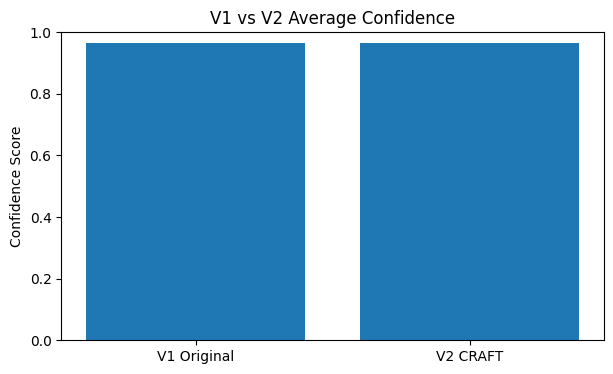

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(
    ["V1 Original", "V2 CRAFT"],
    [
        v1_df["confidence"].mean(),
        v2_df["confidence"].mean()
    ]
)

plt.title("V1 vs V2 Average Confidence")
plt.ylabel("Confidence Score")
plt.ylim(0, 1)
plt.show()

In [ ]:
final_report = pd.DataFrame({
    "Metric": [
        "Total Notes",
        "Root Cause Agreement",
        "Agreement Percentage",
        "V1 Average Confidence",
        "V2 Average Confidence"
    ],
    "Value": [
        len(comparison_df),
        agreement,
        agreement_pct,
        v1_df["confidence"].mean(),
        v2_df["confidence"].mean()
    ]
})

display(final_report)

final_report.to_csv(
    "Final_Prompt_Comparison_Report.csv",
    index=False
)

print("Final Report Saved Successfully!")

,Metric,Value
0,Total Notes,2.000
1,Root Cause Agreement,2.000
2,Agreement Percentage,100.000
3,V1 Average Confidence,0.965
4,V2 Average Confidence,0.965


Final Report Saved Successfully!


## Task 4.3 (B) — Final Conclusion

The V1 Original Prompt and V2 CRAFT Prompt were compared using two selected patient notes (N007 and N009).

### Key Findings

1. Both prompts achieved 100% Root Cause Agreement.
2. Both prompts produced identical confidence scores.
3. Average confidence for both prompts was 0.965.
4. V2 generated more detailed summaries and recommended actions.
5. Both prompts successfully identified the same root cause categories.

### Conclusion

The comparison shows that both prompts produced consistent results for the two selected notes. The V2 CRAFT Prompt provided more detailed and structured recommendations while maintaining the same classification and confidence scores.

**Note:** These findings are based on only two selected notes and cannot establish overall prompt superiority.

In [ ]:
import pandas as pd

# Load both datasets
notes_df = pd.read_csv("/content/notes_analysed.csv")
appointments_df = pd.read_csv("/content/appointments_clean.csv")

print("Notes Shape:", notes_df.shape)
print("Appointments Shape:", appointments_df.shape)

print("\nDatasets Loaded Successfully!")

Notes Shape: (10, 8)
Appointments Shape: (990, 16)

Datasets Loaded Successfully!


In [ ]:
merged_df = pd.merge(
    notes_df,
    appointments_df,
    on="appointment_id",
    how="left"
)

print("Merged Dataset Shape:", merged_df.shape)

display(merged_df.head())

Merged Dataset Shape: (10, 23)


,note_id,appointment_id,root_cause,confidence,summary,recommended_action,validation_status,raw_response,patient_id,clinic_id,...,gender,distance_km,fee_inr,booking_channel,visit_type,reminder_sent,prior_no_shows,status,lead_days,no_show
0,N001,A0872,forgot_or_no_reminder,0.98,Patient forgot the appointment after not recei...,Verify contact information for reminder delive...,valid,"{""note_id"": ""N001"", ""root_cause"": ""forgot_or_n...",P144,C05,...,F,17.6,750,App,Consultation,No,1,No-Show,14,1
1,N002,A0897,distance_or_transport,0.95,Patient missed the appointment due to living f...,Offer telehealth appointment options or assist...,valid,"{""note_id"": ""N002"", ""root_cause"": ""distance_or...",P268,C07,...,M,17.2,1219,Phone,Follow-up,No,0,No-Show,5,1
2,N003,A0526,cost_or_fee,0.98,Patient skipped the visit due to high consulta...,Inform the patient about available financial a...,valid,"{""note_id"": ""N003"", ""root_cause"": ""cost_or_fee...",P006,C04,...,F,5.3,800,App,Consultation,Yes,0,No-Show,34,1
3,N004,A0926,other,0.00,No note recorded,Re-call patient,skipped_blank,NaN,P449,C04,...,M,4.5,300,Phone,Follow-up,No,0,No-Show,40,1
4,N005,A0534,illness_or_emergency,1.00,Patient missed the appointment due to experien...,Contact the patient to reschedule the visit on...,valid,"{""note_id"": ""N005"", ""root_cause"": ""illness_or_...",P400,C04,...,F,4.2,550,App,Follow-up,Yes,0,No-Show,26,1


In [ ]:
# Cross-tabulation
root_cause_reminder = pd.crosstab(
    merged_df["root_cause"],
    merged_df["reminder_sent"]
)

print("Root Cause vs Reminder Sent:")
display(root_cause_reminder)

Root Cause vs Reminder Sent:


reminder_sent,No,Yes
root_cause,,
cost_or_fee,0,1
distance_or_transport,1,1
forgot_or_no_reminder,2,0
illness_or_emergency,0,1
other,1,1
work_or_schedule,1,1


In [ ]:
# Cross-tabulation
root_cause_reminder = pd.crosstab(
    merged_df["root_cause"],
    merged_df["reminder_sent"]
)

print("Root Cause vs Reminder Sent:")
display(root_cause_reminder)

Root Cause vs Reminder Sent:


reminder_sent,No,Yes
root_cause,,
cost_or_fee,0,1
distance_or_transport,1,1
forgot_or_no_reminder,2,0
illness_or_emergency,0,1
other,1,1
work_or_schedule,1,1


In [ ]:
root_cause_reminder.to_csv(
    "root_cause_reminder.csv"
)

print("Cross-tabulation Saved Successfully!")

Cross-tabulation Saved Successfully!


In [ ]:
print("PART 4 FINDINGS")

print("Total Notes:", len(notes_df))

print("Valid Analyses:",
      (notes_df["validation_status"] == "valid").sum())

print("Root Cause Distribution:")
print(notes_df["root_cause"].value_counts())

print("\nReminder Analysis:")
print(root_cause_reminder)

PART 4 FINDINGS
Total Notes: 10
Valid Analyses: 9
Root Cause Distribution:
root_cause
forgot_or_no_reminder    2
distance_or_transport    2
other                    2
work_or_schedule         2
cost_or_fee              1
illness_or_emergency     1
Name: count, dtype: int64

Reminder Analysis:
reminder_sent          No  Yes
root_cause                    
cost_or_fee             0    1
distance_or_transport   1    1
forgot_or_no_reminder   2    0
illness_or_emergency    0    1
other                   1    1
work_or_schedule        1    1
